# Inferência Neurofisiológica e Fisiológica (Tarefa de Stroop)

Este passo cruza os dados demográficos da amostra analítica rigorosa ($N=51$, excluindo atletas de modalidades individuais) com os descritores biológicos extraídos durante a tarefa de Stroop (variáveis hemodinâmicas do fNIRS e biossinais periféricos SPA).

**Estratégia Analítica:**
1. **Filtro de Variáveis:** Isolamento automático de concentrações e amplitudes (`HbO_*_Beta`, `GSR_*`, `HR_*`), ignorando p-values do GLM de 1º nível e canais rejeitados.
2. **Estatística de Contraste:** Aplicação do **Teste *t* de Welch** para amostras independentes, adequado para lidar com a heterogeneidade de variâncias e as ligeiras assimetrias na dimensão dos grupos (A vs. C; AB vs. C).
3. **Magnitude das Diferenças:** Cálculo do **Hedges' *g*** para o tamanho do efeito, por ser o estimador mais robusto para amostras com $N < 50$ por braço.
4. **Controlo de Erro (FDR):** Aplicação da correção de **Holm-Bonferroni** ao valor de $p$ para controlar o Erro do Tipo I face às múltiplas comparações (dezenas de canais medidos em simultâneo).

In [6]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (À Prova de Balas)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"

caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline inferencial para os dados SPA-fNIRS (Stroop)...")

# Ler Base Demográfica
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

# Ler Base Stroop (Lidar com CSVs em português: separador ';' e decimais ',')
if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5:  # Se falhou a leitura por ';', tentar o padrão americano
        df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Padronização de IDs e Definição da Amostra (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

# Limpeza de IDs (garante que "1.0" , "1" e " 1 " ficam exatamente iguais)
df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

print(f"-> Sujeitos no Demográfico: {len(df_demo)}")
print(f"-> Sujeitos no Stroop fNIRS: {len(df_stroop)}")

# Padronização e Exclusão
df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# Grupos
df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB'

df_mapeamento = pd.concat([
    df_analitica[['ID_Clean', 'Grupo_Análise']],
    df_fut[['ID_Clean', 'Grupo_Análise']]
], ignore_index=True)

# ==========================================================
# 3. Merge e Tratamento Forçado de Variáveis
# ==========================================================
df_master = pd.merge(df_mapeamento, df_stroop, on='ID_Clean', how='inner')
print(f"-> Merge concluído! Cruzamos perfis com dados fNIRS de {len(df_master['ID_Clean'].unique())} sujeitos válidos.")

# Encontrar as colunas biológicas APENAS PELO NOME (resolve o problema do Pandas)
variaveis_alvo = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

# Forçar para Numérico: substituir possíveis vírgulas europeias por pontos e converter
for var in variaveis_alvo:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

print(f"-> Analisando {len(variaveis_alvo)} variáveis neurofisiológicas em segurança...\n")

# ==========================================================
# 4. Estatística Inferencial: Welch t-test & Hedges' g (Ultra Robusto)
# ==========================================================
resultados = []

def extrair_stats(res_df):
    """Extrai t, gl, p-value e tamanho de efeito ignorando variações de nome na biblioteca."""
    if res_df is None or res_df.empty:
        return np.nan, np.nan, np.nan, np.nan
        
    cols = [str(c).lower().strip() for c in res_df.columns]
    
    # 1. Encontrar T
    try:
        col_t = res_df.columns[[i for i, c in enumerate(cols) if c in ['t', 't-val', 'tval']][0]]
    except IndexError:
        col_t = res_df.columns[0] # Posição habitual
        
    # 2. Encontrar Graus de Liberdade (dof)
    try:
        col_dof = res_df.columns[[i for i, c in enumerate(cols) if 'dof' in c or 'df' in c][0]]
    except IndexError:
        col_dof = res_df.columns[1] # Posição habitual
        
    # 3. Encontrar P-value
    try:
        col_p = res_df.columns[[i for i, c in enumerate(cols) if c in ['p-val', 'pval', 'p', 'p-value'] or c.startswith('p')][0]]
    except IndexError:
        col_p = res_df.columns[3] # Posição habitual
        
    # 4. Encontrar Tamanho de Efeito
    try:
        col_es = res_df.columns[[i for i, c in enumerate(cols) if 'hedge' in c or 'cohen' in c or 'es' in c or c == 'd'][0]]
    except IndexError:
        col_es = res_df.columns[5] # Posição habitual
        
    return res_df[col_t].values[0], res_df[col_dof].values[0], res_df[col_p].values[0], res_df[col_es].values[0]

for var in variaveis_alvo:
    df_var = df_master[['Grupo_Análise', var]].dropna()
    
    x_A = df_var[df_var['Grupo_Análise'] == 'A'][var].values
    x_AB = df_var[df_var['Grupo_Análise'] == 'AB'][var].values
    x_C = df_var[df_var['Grupo_Análise'] == 'C'][var].values
    
    # 4.1 Contraste: Grupo A vs C
    if len(x_A) >= 3 and len(x_C) >= 3:
        try:
            res_AC = pg.ttest(x_A, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_AC)
            
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo A vs C',
                    'N_G1': len(x_A), 'Média_G1': np.mean(x_A), 'DP_G1': np.std(x_A, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val,
                    'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception:
            pass # Ignorar se o teste falhar (ex: dados constantes/variância zero nesta variável)
        
    # 4.2 Contraste: Subgrupo AB vs C
    if len(x_AB) >= 3 and len(x_C) >= 3:
        try:
            res_ABC = pg.ttest(x_AB, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_ABC)
            
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo AB vs C',
                    'N_G1': len(x_AB), 'Média_G1': np.mean(x_AB), 'DP_G1': np.std(x_AB, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val,
                    'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception:
            pass

df_res = pd.DataFrame(resultados)

# ==========================================================
# 5. Correção de Holm-Bonferroni (FDR)
# ==========================================================
if not df_res.empty:
    df_AC = df_res[df_res['Contraste'] == 'Grupo A vs C'].copy()
    df_ABC = df_res[df_res['Contraste'] == 'Grupo AB vs C'].copy()
    
    # Holm A vs C
    if not df_AC.empty:
        rej_AC, pval_corr_AC = pg.multicomp(df_AC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_AC['p-Holm'] = pval_corr_AC
        df_AC['Significativo'] = rej_AC
    
    # Holm AB vs C
    if not df_ABC.empty:
        rej_ABC, pval_corr_ABC = pg.multicomp(df_ABC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_ABC['p-Holm'] = pval_corr_ABC
        df_ABC['Significativo'] = rej_ABC
    
    # Agrupar e ordenar a tabela final
    df_final = pd.concat([df_AC, df_ABC]).sort_values(by=['Variável', 'Contraste'])
    
    cols_format = ['Média_G1', 'DP_G1', 'Média_G2', 'DP_G2', 't', 'gl', 'p-uncorrected', 'p-Holm', 'Hedges_g']
    df_final[cols_format] = df_final[cols_format].round(4)
    
    ficheiro_saida = pasta_resultados / "Comparacoes_Neurofisiologicas_Welch_Holm_Stroop.xlsx"
    df_final.to_excel(ficheiro_saida, index=False)
    
    print("="*60)
    print("ANÁLISE INFERENCIAL CONCLUÍDA (STROOP: fNIRS + Fisiologia)")
    print("="*60)
    print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")
    
    achados = df_final[df_final['Significativo'] == True]
    if not achados.empty:
        print("[!] Achados Estatisticamente Significativos (p-Holm < 0.05):")
        from IPython.display import display
        display(achados[['Variável', 'Contraste', 'Média_G1', 'Média_G2', 'p-Holm', 'Hedges_g']])
    else:
        print("[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).")
else:
    print("Não foram gerados resultados para exportar.")

A iniciar o pipeline inferencial para os dados SPA-fNIRS (Stroop)...
-> Sujeitos no Demográfico: 54
-> Sujeitos no Stroop fNIRS: 53
-> Merge concluído! Cruzamos perfis com dados fNIRS de 50 sujeitos válidos.
-> Analisando 68 variáveis neurofisiológicas em segurança...

ANÁLISE INFERENCIAL CONCLUÍDA (STROOP: fNIRS + Fisiologia)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_Stroop.xlsx

[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).


# Inferência Neurofisiológica e Fisiológica (Tarefa de Decision Making)

Aplicação do pipeline inferencial validado à tarefa de Tomada de Decisão (Decision Making). Cruzamento dos dados demográficos da amostra analítica ($N=51$) com os descritores biológicos (fNIRS e SPA).

**Estratégia Analítica:**
1. **Filtro de Variáveis Biológicas** (`HbO_*_Beta`, `GSR_*`, `HR_*`).
2. **Estatística de Contraste:** Teste *t* de Welch para amostras independentes (A vs. C; AB vs. C).
3. **Tamanho do Efeito:** Cálculo do Hedges' *g*.
4. **Controlo de Erro (FDR):** Correção de Holm-Bonferroni aplicada de forma independente a cada família de contrastes.

In [1]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (Decision Making)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"

caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline inferencial para os dados SPA-fNIRS (DECISION MAKING)...")

# Ler Base Demográfica
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

# Ler Base Decision Making
if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5:  
        df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# ==========================================================
# 2. Padronização de IDs e Definição da Amostra (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

print(f"-> Sujeitos no Demográfico: {len(df_demo)}")
print(f"-> Sujeitos no Decision Making fNIRS: {len(df_dm)}")

# Padronização e Exclusão
df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# Grupos
df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB'

df_mapeamento = pd.concat([
    df_analitica[['ID_Clean', 'Grupo_Análise']],
    df_fut[['ID_Clean', 'Grupo_Análise']]
], ignore_index=True)

# ==========================================================
# 3. Merge e Tratamento Forçado de Variáveis
# ==========================================================
df_master = pd.merge(df_mapeamento, df_dm, on='ID_Clean', how='inner')
print(f"-> Merge concluído! Cruzamos perfis com dados de {len(df_master['ID_Clean'].unique())} sujeitos válidos.")

variaveis_alvo = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

for var in variaveis_alvo:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

print(f"-> Analisando {len(variaveis_alvo)} variáveis neurofisiológicas em segurança...\n")

# ==========================================================
# 4. Estatística Inferencial (Função Robusta)
# ==========================================================
resultados = []

def extrair_stats(res_df):
    if res_df is None or res_df.empty: return np.nan, np.nan, np.nan, np.nan
    cols = [str(c).lower().strip() for c in res_df.columns]
    try: col_t = res_df.columns[[i for i, c in enumerate(cols) if c in ['t', 't-val', 'tval']][0]]
    except IndexError: col_t = res_df.columns[0]
    try: col_dof = res_df.columns[[i for i, c in enumerate(cols) if 'dof' in c or 'df' in c][0]]
    except IndexError: col_dof = res_df.columns[1]
    try: col_p = res_df.columns[[i for i, c in enumerate(cols) if c in ['p-val', 'pval', 'p', 'p-value'] or c.startswith('p')][0]]
    except IndexError: col_p = res_df.columns[3]
    try: col_es = res_df.columns[[i for i, c in enumerate(cols) if 'hedge' in c or 'cohen' in c or 'es' in c or c == 'd'][0]]
    except IndexError: col_es = res_df.columns[5]
    return res_df[col_t].values[0], res_df[col_dof].values[0], res_df[col_p].values[0], res_df[col_es].values[0]

for var in variaveis_alvo:
    df_var = df_master[['Grupo_Análise', var]].dropna()
    x_A = df_var[df_var['Grupo_Análise'] == 'A'][var].values
    x_AB = df_var[df_var['Grupo_Análise'] == 'AB'][var].values
    x_C = df_var[df_var['Grupo_Análise'] == 'C'][var].values
    
    if len(x_A) >= 3 and len(x_C) >= 3:
        try:
            res_AC = pg.ttest(x_A, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_AC)
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo A vs C',
                    'N_G1': len(x_A), 'Média_G1': np.mean(x_A), 'DP_G1': np.std(x_A, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val, 'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception: pass
        
    if len(x_AB) >= 3 and len(x_C) >= 3:
        try:
            res_ABC = pg.ttest(x_AB, x_C, correction=True)
            t_val, gl_val, pval, hedges_val = extrair_stats(res_ABC)
            if pd.notna(pval):
                resultados.append({
                    'Variável': var, 'Contraste': 'Grupo AB vs C',
                    'N_G1': len(x_AB), 'Média_G1': np.mean(x_AB), 'DP_G1': np.std(x_AB, ddof=1),
                    'N_G2': len(x_C), 'Média_G2': np.mean(x_C), 'DP_G2': np.std(x_C, ddof=1),
                    't': t_val, 'gl': gl_val, 'p-uncorrected': pval, 'Hedges_g': hedges_val
                })
        except Exception: pass

df_res = pd.DataFrame(resultados)

# ==========================================================
# 5. Correção de Holm-Bonferroni (FDR) e Exportação
# ==========================================================
if not df_res.empty:
    df_AC = df_res[df_res['Contraste'] == 'Grupo A vs C'].copy()
    df_ABC = df_res[df_res['Contraste'] == 'Grupo AB vs C'].copy()
    
    if not df_AC.empty:
        rej_AC, pval_corr_AC = pg.multicomp(df_AC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_AC['p-Holm'] = pval_corr_AC
        df_AC['Significativo'] = rej_AC
    
    if not df_ABC.empty:
        rej_ABC, pval_corr_ABC = pg.multicomp(df_ABC['p-uncorrected'].values, alpha=0.05, method='holm')
        df_ABC['p-Holm'] = pval_corr_ABC
        df_ABC['Significativo'] = rej_ABC
    
    df_final = pd.concat([df_AC, df_ABC]).sort_values(by=['Variável', 'Contraste'])
    cols_format = ['Média_G1', 'DP_G1', 'Média_G2', 'DP_G2', 't', 'gl', 'p-uncorrected', 'p-Holm', 'Hedges_g']
    df_final[cols_format] = df_final[cols_format].round(4)
    
    ficheiro_saida = pasta_resultados / "Comparacoes_Neurofisiologicas_Welch_Holm_DecisionMaking.xlsx"
    df_final.to_excel(ficheiro_saida, index=False)
    
    print("="*60)
    print("ANÁLISE INFERENCIAL CONCLUÍDA (DECISION MAKING: fNIRS + Fisiologia)")
    print("="*60)
    print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")
    
    achados = df_final[df_final['Significativo'] == True]
    if not achados.empty:
        print("[!] Achados Estatisticamente Significativos (p-Holm < 0.05):")
        from IPython.display import display
        display(achados[['Variável', 'Contraste', 'Média_G1', 'Média_G2', 'p-Holm', 'Hedges_g']])
    else:
        print("[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).")
else:
    print("Não foram gerados resultados para exportar.")

A iniciar o pipeline inferencial para os dados SPA-fNIRS (DECISION MAKING)...
-> Sujeitos no Demográfico: 54
-> Sujeitos no Decision Making fNIRS: 54
-> Merge concluído! Cruzamos perfis com dados de 51 sujeitos válidos.
-> Analisando 24 variáveis neurofisiológicas em segurança...

ANÁLISE INFERENCIAL CONCLUÍDA (DECISION MAKING: fNIRS + Fisiologia)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Comparacoes_Neurofisiologicas_Welch_Holm_DecisionMaking.xlsx

[i] Não foram encontrados resultados significativos após controlo rigoroso de FDR (Holm-Bonferroni).


# Fase 9: Correlações Cérebro-Comportamento (Stroop)

Dado que a inferência baseada na comparação de grupos (Coletivos vs. Não-Atletas) não revelou diferenças significativas após o controlo rigoroso de FDR, a estratégia analítica transita para o estudo de associações contínuas entre a neurofisiologia e o rendimento cognitivo (*Brain-Behavior Correlations*).

**Estratégia Analítica:**
1. **Integração Multimodal:** Fusão dos *outcomes* comportamentais globais da tarefa de Stroop (`ST_Acc_N_Total`, `ST_RT_Medio_Total_seg`) com os descritores biológicos do fNIRS e SPA.
2. **Matriz de Correlações:** Cálculo de correlações de Spearman (robustas a desvios de normalidade e *outliers*) entre o desempenho psicomotor e a ativação cortical/fisiológica, analisando a amostra analítica global ($N=51$).
3. **Controlo de Erro (FDR):** Aplicação de Holm-Bonferroni aos *p-values* da matriz de correlações.
4. **Exportação:** Geração de um relatório com as associações mais fortes (significativas e tendências com moderado tamanho de efeito).

In [3]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (Stroop)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"
caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx

pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline de Correlações Cérebro-Comportamento (Stroop)...")

# Ler Base Demográfica
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

# Ler Base Stroop fNIRS
if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5:  
        df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Limpeza de IDs e Filtragem da Amostra (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

# Excluir Individuais
df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# ==========================================================
# 3. Merge: Comportamento + Fisiologia
# ==========================================================
vars_comportamento = ['ID_Clean', 'ST_Acc_N_Total', 'ST_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_stroop, on='ID_Clean', how='inner')

variaveis_neuro = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

# Forçar conversão numérica segura
for var in variaveis_neuro + ['ST_Acc_N_Total', 'ST_RT_Medio_Total_seg']:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=['ST_Acc_N_Total', 'ST_RT_Medio_Total_seg'])
print(f"-> Analisando correlações para {len(df_master)} sujeitos válidos...\n")

# ==========================================================
# 4. Matriz de Correlação (Spearman) Robusta
# ==========================================================
# Precisão (Accuracy)
corr_acc = pg.pairwise_corr(df_master, columns=[['ST_Acc_N_Total'], variaveis_neuro], method='spearman')

# Extração dinâmica do nome da coluna do p-value
p_col_acc = [c for c in corr_acc.columns if c.startswith('p') and c != 'power'][0]
corr_acc = corr_acc[['X', 'Y', 'n', 'r', p_col_acc]].copy()
corr_acc.rename(columns={p_col_acc: 'p-unc'}, inplace=True)
corr_acc['Comportamento'] = 'Precisão (Acc_N)'

# Tempo de Reação (RT)
corr_rt = pg.pairwise_corr(df_master, columns=[['ST_RT_Medio_Total_seg'], variaveis_neuro], method='spearman')
p_col_rt = [c for c in corr_rt.columns if c.startswith('p') and c != 'power'][0]
corr_rt = corr_rt[['X', 'Y', 'n', 'r', p_col_rt]].copy()
corr_rt.rename(columns={p_col_rt: 'p-unc'}, inplace=True)
corr_rt['Comportamento'] = 'Tempo de Reação (RT)'

# Combinar matrizes
df_corr = pd.concat([corr_acc, corr_rt], ignore_index=True)
df_corr.rename(columns={'X': 'Variável_Comportamental', 'Y': 'Variável_Neurofisiológica', 'r': 'Rho (Spearman)'}, inplace=True)

# ==========================================================
# 5. Controlo de Erro (FDR Holm-Bonferroni)
# ==========================================================
df_corr['p-Holm'] = np.nan
df_corr['Significativo'] = False

# FDR Precisão
rej_acc, pval_corr_acc = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-Holm'] = pval_corr_acc
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'Significativo'] = rej_acc

# FDR Tempo de Reação
rej_rt, pval_corr_rt = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-Holm'] = pval_corr_rt
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'Significativo'] = rej_rt

# Ordenar pelas correlações mais fortes (Rho absoluto)
df_corr['|Rho|'] = df_corr['Rho (Spearman)'].abs()
df_corr = df_corr.sort_values(by=['Comportamento', '|Rho|'], ascending=[True, False]).drop(columns=['|Rho|'])

cols_format = ['Rho (Spearman)', 'p-unc', 'p-Holm']
df_corr[cols_format] = df_corr[cols_format].round(4)

# ==========================================================
# 6. Exportação
# ==========================================================
ficheiro_saida = pasta_resultados / "Correlacoes_Cerebro_Comportamento_Stroop.xlsx"
df_corr.to_excel(ficheiro_saida, index=False)

print("="*60)
print("MATRIZ DE CORRELAÇÃO CONCLUÍDA (STROOP)")
print("="*60)
print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")

# Destacar resultados com tamanho de efeito moderado ou forte (rho > 0.30 na Psicologia do Desporto é um achado sólido)
achados_fortes = df_corr[(df_corr['Significativo'] == True) | (df_corr['Rho (Spearman)'].abs() >= 0.30)]

if not achados_fortes.empty:
    print("[!] Correlações Significativas ou Moderadas (|rho| >= 0.30):")
    from IPython.display import display
    display(achados_fortes[['Variável_Comportamental', 'Variável_Neurofisiológica', 'Rho (Spearman)', 'p-unc', 'p-Holm']])
else:
    print("[i] Não foram detetadas correlações moderadas a fortes (|rho| >= 0.30).")

A iniciar o pipeline de Correlações Cérebro-Comportamento (Stroop)...
-> Analisando correlações para 50 sujeitos válidos...

MATRIZ DE CORRELAÇÃO CONCLUÍDA (STROOP)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Correlacoes_Cerebro_Comportamento_Stroop.xlsx

[!] Correlações Significativas ou Moderadas (|rho| >= 0.30):


,Variável_Comportamental,Variável_Neurofisiológica,Rho (Spearman),p-unc,p-Holm
0,ST_Acc_N_Total,GSR_Media_Con,0.3317,0.0186,1.0000
67,ST_Acc_N_Total,HbO_S3_D2_Inc-Con_Beta,0.3039,0.0600,1.0000
80,ST_RT_Medio_Total_seg,HbO_S1_D2_Con_Beta,0.4117,0.0075,0.5019
68,ST_RT_Medio_Total_seg,GSR_Media_Con,-0.3770,0.0070,0.4733
69,ST_RT_Medio_Total_seg,GSR_Amplitude_Con,-0.3667,0.0088,0.5812
70,ST_RT_Medio_Total_seg,GSR_Media_Inc,-0.3448,0.0142,0.9225
71,ST_RT_Medio_Total_seg,GSR_Amplitude_Inc,-0.3329,0.0182,1.0000
124,ST_RT_Medio_Total_seg,HbO_S7_D7_Inc_Beta,0.3219,0.0226,1.0000


# Fase 9b: Correlações Cérebro-Comportamento (Decision Making)

Integração multimodal dos *outcomes* comportamentais da tarefa de Tomada de Decisão (`DM_Acc_N_Total`, `DM_RT_Medio_Total_seg`) com os marcadores de ativação do fNIRS e da Fisiologia Periférica (SPA).

**Estratégia Analítica:**
1. Cálculo de correlações de Spearman (não-paramétricas) na amostra analítica global ($N=51$).
2. Aplicação de FDR (Holm-Bonferroni) estratificado por dimensão comportamental (Precisão vs. Tempo de Reação).
3. Exportação e mapeamento de correlações com tamanho de efeito moderado a forte ($|rho| \ge 0.30$), cruciais para compreender a eficiência neural (*Neural Efficiency Hypothesis*) no desporto.

In [4]:
import os
import pandas as pd
import numpy as np
import pingouin as pg
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')

# ==========================================================
# 1. Configuração e Carregamento (Decision Making)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
pasta_resultados.mkdir(parents=True, exist_ok=True)

print("A iniciar o pipeline de Correlações Cérebro-Comportamento (Decision Making)...")

# Ler Base Demográfica e DM fNIRS
if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# ==========================================================
# 2. Amostra Analítica (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

# ==========================================================
# 3. Merge: Comportamento + Fisiologia
# ==========================================================
# ATENÇÃO: Mudança dos nomes das colunas de comportamento para a tarefa de DM
vars_comportamento = ['ID_Clean', 'DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_dm, on='ID_Clean', how='inner')

variaveis_neuro = [col for col in df_master.columns if (
    col.startswith('GSR_') or 
    col.startswith('HR_') or 
    (col.startswith('HbO_') and col.endswith('_Beta'))
)]

# Forçar conversão
for var in variaveis_neuro + ['DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']:
    if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
        df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=['DM_Acc_N_Total', 'DM_RT_Medio_Total_seg'])
print(f"-> Analisando correlações para {len(df_master)} sujeitos válidos...\n")

# ==========================================================
# 4. Matriz de Correlação (Spearman)
# ==========================================================
# Precisão
corr_acc = pg.pairwise_corr(df_master, columns=[['DM_Acc_N_Total'], variaveis_neuro], method='spearman')
p_col_acc = [c for c in corr_acc.columns if c.startswith('p') and c != 'power'][0]
corr_acc = corr_acc[['X', 'Y', 'n', 'r', p_col_acc]].copy()
corr_acc.rename(columns={p_col_acc: 'p-unc'}, inplace=True)
corr_acc['Comportamento'] = 'Precisão (Acc_N)'

# Tempo de Reação
corr_rt = pg.pairwise_corr(df_master, columns=[['DM_RT_Medio_Total_seg'], variaveis_neuro], method='spearman')
p_col_rt = [c for c in corr_rt.columns if c.startswith('p') and c != 'power'][0]
corr_rt = corr_rt[['X', 'Y', 'n', 'r', p_col_rt]].copy()
corr_rt.rename(columns={p_col_rt: 'p-unc'}, inplace=True)
corr_rt['Comportamento'] = 'Tempo de Reação (RT)'

df_corr = pd.concat([corr_acc, corr_rt], ignore_index=True)
df_corr.rename(columns={'X': 'Variável_Comportamental', 'Y': 'Variável_Neurofisiológica', 'r': 'Rho (Spearman)'}, inplace=True)

# ==========================================================
# 5. Controlo de Erro (FDR Holm-Bonferroni)
# ==========================================================
df_corr['p-Holm'] = np.nan
df_corr['Significativo'] = False

# Holm Precisão
rej_acc, pval_corr_acc = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'p-Holm'] = pval_corr_acc
df_corr.loc[df_corr['Comportamento'] == 'Precisão (Acc_N)', 'Significativo'] = rej_acc

# Holm Tempo de Reação
rej_rt, pval_corr_rt = pg.multicomp(df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-unc'].values, alpha=0.05, method='holm')
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'p-Holm'] = pval_corr_rt
df_corr.loc[df_corr['Comportamento'] == 'Tempo de Reação (RT)', 'Significativo'] = rej_rt

df_corr['|Rho|'] = df_corr['Rho (Spearman)'].abs()
df_corr = df_corr.sort_values(by=['Comportamento', '|Rho|'], ascending=[True, False]).drop(columns=['|Rho|'])

cols_format = ['Rho (Spearman)', 'p-unc', 'p-Holm']
df_corr[cols_format] = df_corr[cols_format].round(4)

# ==========================================================
# 6. Exportação
# ==========================================================
ficheiro_saida = pasta_resultados / "Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx"
df_corr.to_excel(ficheiro_saida, index=False)

print("="*60)
print("MATRIZ DE CORRELAÇÃO CONCLUÍDA (DECISION MAKING)")
print("="*60)
print(f"-> Exportado para: {ficheiro_saida.resolve()}\n")

achados_fortes = df_corr[(df_corr['Significativo'] == True) | (df_corr['Rho (Spearman)'].abs() >= 0.30)]

if not achados_fortes.empty:
    print("[!] Correlações Significativas ou Moderadas (|rho| >= 0.30):")
    from IPython.display import display
    display(achados_fortes[['Variável_Comportamental', 'Variável_Neurofisiológica', 'Rho (Spearman)', 'p-unc', 'p-Holm']])
else:
    print("[i] Não foram detetadas correlações moderadas a fortes (|rho| >= 0.30).")

A iniciar o pipeline de Correlações Cérebro-Comportamento (Decision Making)...
-> Analisando correlações para 51 sujeitos válidos...

MATRIZ DE CORRELAÇÃO CONCLUÍDA (DECISION MAKING)
-> Exportado para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx

[i] Não foram detetadas correlações moderadas a fortes (|rho| >= 0.30).


# Fase 10: Visualização de Correlações Cérebro-Comportamento (Stroop)

Com base na matriz de correlações de Spearman, procedeu-se à representação visual das associações neurofisiológicas com maior magnitude (Top 3) na tarefa de Stroop.

**Estratégia Visual:**
* Construção de *Scatter Plots* (Gráficos de Dispersão) para mapear os scores individuais na dimensão comportamental (Eixo X) e neurofisiológica (Eixo Y).
* Inclusão de linha de regressão linear para ilustrar a direção da tendência (positiva/negativa) e sombreamento do intervalo de confiança (95% CI).
* Formatação académica (*Times New Roman*, alta resolução, remoção de *gridlines* desnecessárias) para inclusão direta no manuscrito.

Gráficos exportados com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\ScatterPlots_Stroop.png


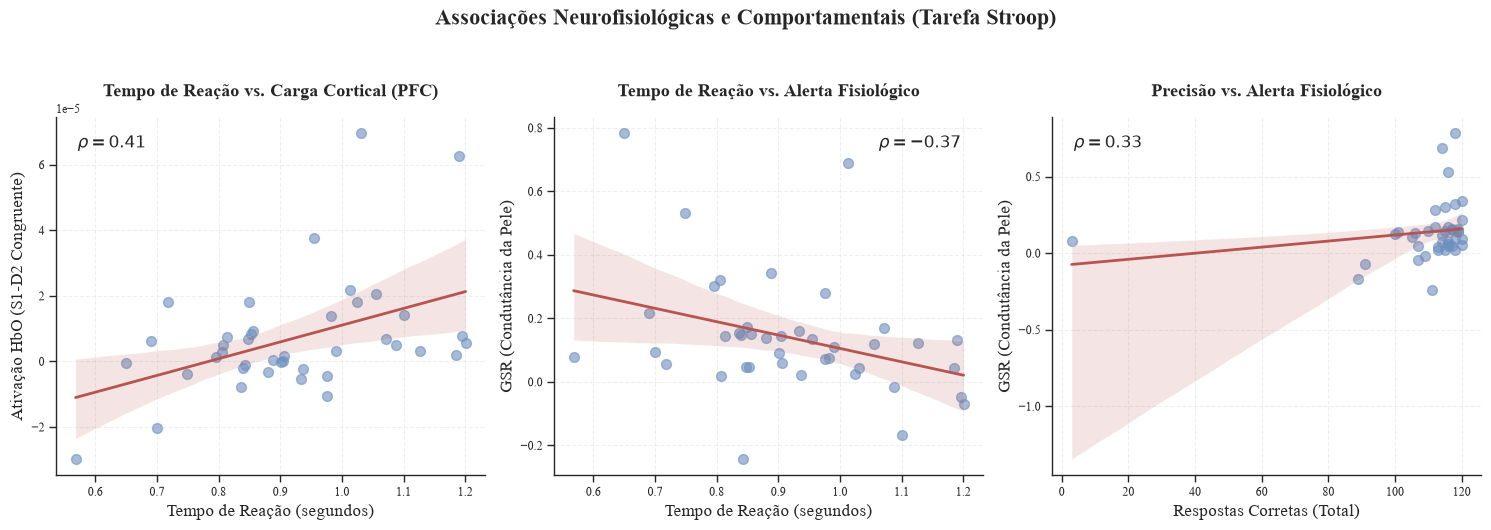

In [5]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Configurar a fonte global para Times New Roman
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura de Dados (Stroop)
# ==========================================================
pasta_dados = Path("../data_subjects")
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"
caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx

pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5:  
        df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Amostra Analítica e Merge (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

vars_comportamento = ['ID_Clean', 'ST_Acc_N_Total', 'ST_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_stroop, on='ID_Clean', how='inner')

# Forçar numéricos nas variáveis alvo para o Top 3
variaveis_alvo = ['ST_Acc_N_Total', 'ST_RT_Medio_Total_seg', 'HbO_S1_D2_Con_Beta', 'GSR_Media_Con']

for var in variaveis_alvo:
    if var in df_master.columns:
        if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
            df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=variaveis_alvo)

# ==========================================================
# 3. Desenho dos Gráficos de Dispersão (Scatter Plots)
# ==========================================================
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Associações Neurofisiológicas e Comportamentais (Tarefa Stroop)", fontsize=16, fontweight='bold', y=1.05)

# Paleta baseada nas tuas cores anteriores, usando um azul académico
cor_pontos = '#6c8ebf' 
cor_linha = '#b85450'

# PLOT 1: Tempo de Reação vs HbO_S1_D2
sns.regplot(
    data=df_master, x='ST_RT_Medio_Total_seg', y='HbO_S1_D2_Con_Beta',
    ax=axes[0], scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[0].set_title("Tempo de Reação vs. Carga Cortical (PFC)", fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel("Tempo de Reação (segundos)", fontsize=12)
axes[0].set_ylabel("Ativação HbO (S1-D2 Congruente)", fontsize=12)
axes[0].text(0.05, 0.95, r'$\rho = 0.41$', transform=axes[0].transAxes, fontsize=12, fontweight='bold', va='top')

# PLOT 2: Tempo de Reação vs GSR
sns.regplot(
    data=df_master, x='ST_RT_Medio_Total_seg', y='GSR_Media_Con',
    ax=axes[1], scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[1].set_title("Tempo de Reação vs. Alerta Fisiológico", fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel("Tempo de Reação (segundos)", fontsize=12)
axes[1].set_ylabel("GSR (Condutância da Pele)", fontsize=12)
axes[1].text(0.95, 0.95, r'$\rho = -0.37$', transform=axes[1].transAxes, fontsize=12, fontweight='bold', ha='right', va='top')

# PLOT 3: Precisão vs GSR
sns.regplot(
    data=df_master, x='ST_Acc_N_Total', y='GSR_Media_Con',
    ax=axes[2], scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
)
axes[2].set_title("Precisão vs. Alerta Fisiológico", fontsize=13, fontweight='bold', pad=15)
axes[2].set_xlabel("Respostas Corretas (Total)", fontsize=12)
axes[2].set_ylabel("GSR (Condutância da Pele)", fontsize=12)
axes[2].text(0.05, 0.95, r'$\rho = 0.33$', transform=axes[2].transAxes, fontsize=12, fontweight='bold', va='top')

# Ajustes finais e limpeza visual
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

# Exportar
caminho_figura = pasta_resultados / "ScatterPlots_Stroop.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"Gráficos exportados com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 10b: Visualização de Correlações Cérebro-Comportamento (Decision Making)

Em contraste com a tarefa de Stroop, a exploração visual da tarefa de *Decision Making* foca-se nas três associações de maior magnitude detetadas na matriz, ilustrando a ausência de predição linear forte entre a atividade pré-frontal/periférica e o desempenho nesta tarefa específica.

**Estratégia Visual:**
* Identificação automática do "Top 3" de correlações (maior *Rho* absoluto) no relatório gerado na Fase 9b.
* Construção de *Scatter Plots* com linha de regressão e sombreamento do intervalo de confiança (95% CI).
* Formatação académica (Times New Roman, 300 DPI) emparelhada com o design da Fase 10.

A carregar matriz de correlações e a isolar o Top 3 do Decision Making...

Gráficos exportados com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\ScatterPlots_DecisionMaking.png


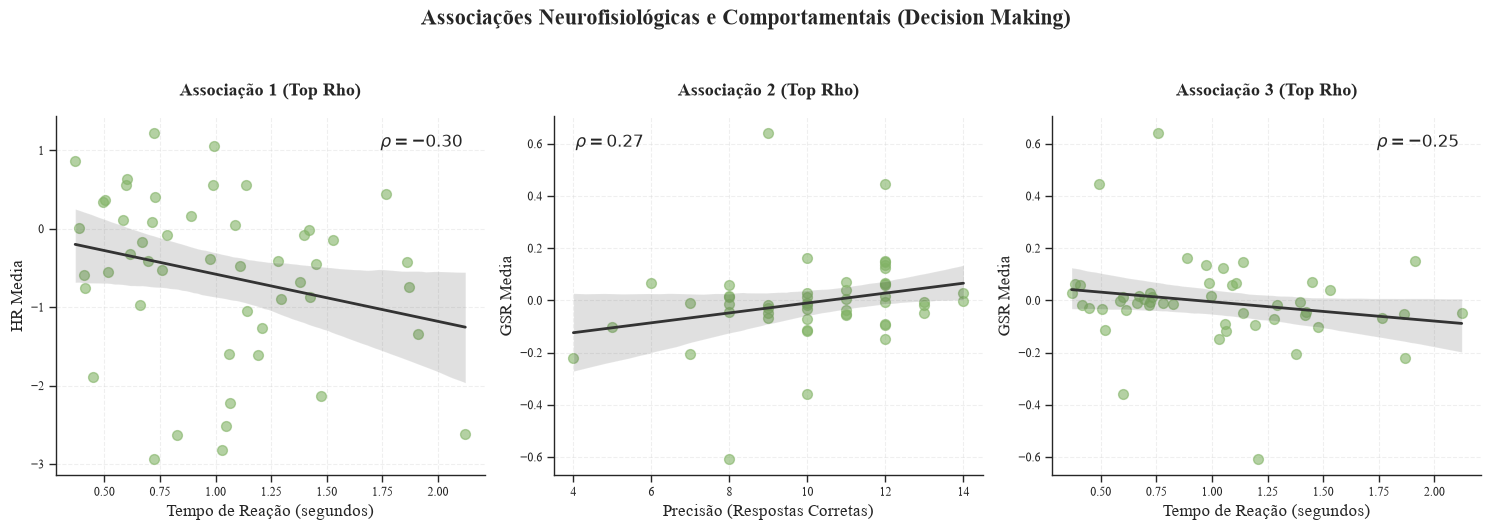

In [6]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

# Configurar a fonte global
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura do Top 3 de Correlações (DM)
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"

caminho_corr = pasta_resultados / "Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx"

print("A carregar matriz de correlações e a isolar o Top 3 do Decision Making...")
df_corr = pd.read_excel(caminho_corr)

# Encontrar as 3 correlações mais fortes (em valor absoluto)
df_corr['Abs_Rho'] = df_corr['Rho (Spearman)'].abs()
top3 = df_corr.sort_values(by='Abs_Rho', ascending=False).head(3).reset_index(drop=True)

# Guardar os pares (Comportamento, Neurofisiologia) e os seus Rhos
pares_plot = []
for i, row in top3.iterrows():
    pares_plot.append({
        'X': row['Variável_Comportamental'],
        'Y': row['Variável_Neurofisiológica'],
        'Rho': row['Rho (Spearman)']
    })

# ==========================================================
# 2. Reconstruir a Amostra Analítica (Merge DM)
# ==========================================================
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"
caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# Limpeza e Filtro N=51
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
else:
    mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
    individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & (~df_demo['Modalidade'].isin(mods_coletivas))].index

df_analitica = df_demo.drop(individuais).copy()

vars_comportamento = ['ID_Clean', 'DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_dm, on='ID_Clean', how='inner')

# Forçar tipo numérico estrito para as variáveis alvo que vão ser desenhadas
vars_para_limpar = [p['X'] for p in pares_plot] + [p['Y'] for p in pares_plot]
for var in set(vars_para_limpar):
    if var in df_master.columns:
        if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
            df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=list(set(vars_para_limpar)))

# ==========================================================
# 3. Desenho dos Gráficos de Dispersão Dinâmicos
# ==========================================================
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle("Associações Neurofisiológicas e Comportamentais (Decision Making)", fontsize=16, fontweight='bold', y=1.05)

# Paleta (cores contrastantes ou idênticas ao Stroop para uniformidade na tese)
cor_pontos = '#82b366' # Um tom esverdeado subtil para distinguir do Stroop
cor_linha = '#333333'

for i, par in enumerate(pares_plot):
    ax = axes[i]
    x_var = par['X']
    y_var = par['Y']
    rho_val = par['Rho']
    
    sns.regplot(
        data=df_master, x=x_var, y=y_var,
        ax=ax, scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
    )
    
    # Nomes dos eixos mais legíveis (traduzir as labels comportamentais)
    xlabel = "Tempo de Reação (segundos)" if "RT" in x_var else "Precisão (Respostas Corretas)"
    ylabel = y_var.replace("_Beta", "").replace("_", " ") # Limpar um pouco o nome do fNIRS/GSR
    
    ax.set_title(f"Associação {i+1} (Top Rho)", fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    
    # Colocar o Rho no canto do gráfico (canto superior esquerdo ou direito consoante a tendência)
    x_pos = 0.05 if rho_val >= 0 else 0.95
    ha_align = 'left' if rho_val >= 0 else 'right'
    ax.text(x_pos, 0.95, f'$\\rho = {rho_val:.2f}$', transform=ax.transAxes, fontsize=12, fontweight='bold', ha=ha_align, va='top')

# Limpeza visual
for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

# Exportar
caminho_figura = pasta_resultados / "ScatterPlots_DecisionMaking.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"\nGráficos exportados com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 10c: Visualização de Correlações Corticais (Decision Making)

Exploração visual focada especificamente nos marcadores hemodinâmicos corticais (fNIRS) durante a tarefa de Tomada de Decisão.
O objetivo é ilustrar o contraste de recrutamento pré-frontal em comparação com a tarefa de Stroop, mapeando a correlação cortical (HbO) mais elevada extraída da matriz.

Top Cortical RT: HbO_S5_D6_Beta (rho = 0.1377)
Top Cortical Acc: HbO_S2_D3_Beta (rho = 0.172)

Gráficos corticais exportados com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\ScatterPlots_Cortical_DecisionMaking.png


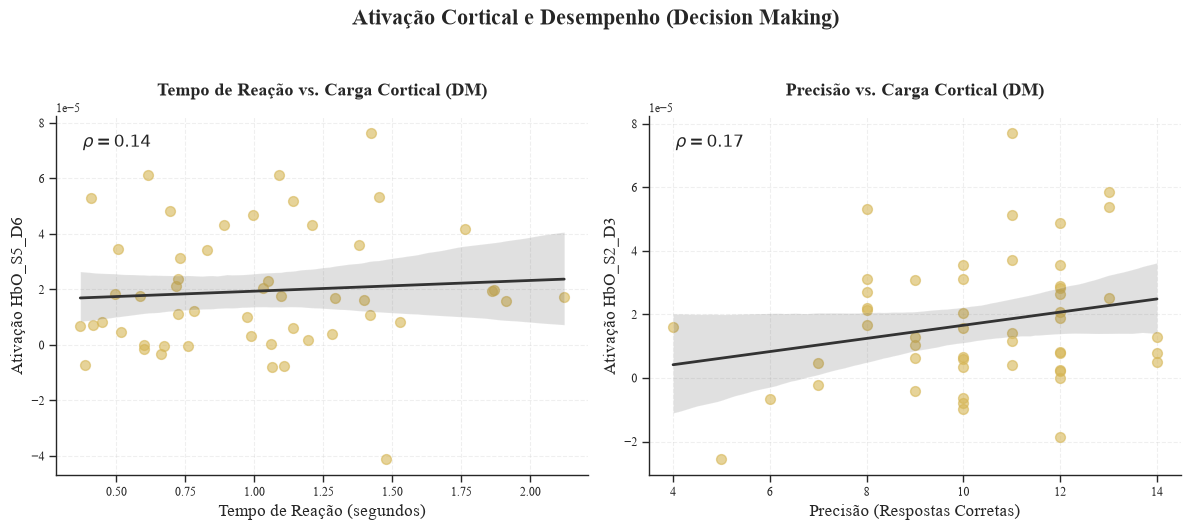

In [7]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Isolar o Melhor Preditivo Cortical (HbO) do DM
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
caminho_corr = pasta_resultados / "Correlacoes_Cerebro_Comportamento_DecisionMaking.xlsx"

df_corr = pd.read_excel(caminho_corr)

# Filtrar APENAS variáveis fNIRS (que comecem por HbO)
df_corr_cortical = df_corr[df_corr['Variável_Neurofisiológica'].str.startswith('HbO')].copy()
df_corr_cortical['Abs_Rho'] = df_corr_cortical['Rho (Spearman)'].abs()

# Extrair a melhor para o Tempo de Reação e a melhor para a Precisão
top_rt = df_corr_cortical[df_corr_cortical['Comportamento'] == 'Tempo de Reação (RT)'].sort_values(by='Abs_Rho', ascending=False).iloc[0]
top_acc = df_corr_cortical[df_corr_cortical['Comportamento'] == 'Precisão (Acc_N)'].sort_values(by='Abs_Rho', ascending=False).iloc[0]

pares_plot = [
    {'X': top_rt['Variável_Comportamental'], 'Y': top_rt['Variável_Neurofisiológica'], 'Rho': top_rt['Rho (Spearman)'], 'Title': 'Tempo de Reação vs. Carga Cortical (DM)'},
    {'X': top_acc['Variável_Comportamental'], 'Y': top_acc['Variável_Neurofisiológica'], 'Rho': top_acc['Rho (Spearman)'], 'Title': 'Precisão vs. Carga Cortical (DM)'}
]

print(f"Top Cortical RT: {top_rt['Variável_Neurofisiológica']} (rho = {top_rt['Rho (Spearman)']})")
print(f"Top Cortical Acc: {top_acc['Variável_Neurofisiológica']} (rho = {top_acc['Rho (Spearman)']})")

# ==========================================================
# 2. Reconstruir a Amostra Analítica (Merge DM)
# ==========================================================
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"
caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset" if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names else 0)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
else:
    is_individual = (~df_demo['Modalidade'].isin(mods_coletivas))

individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
df_analitica = df_demo.drop(individuais).copy()

vars_comportamento = ['ID_Clean', 'DM_Acc_N_Total', 'DM_RT_Medio_Total_seg']
df_master = pd.merge(df_analitica[vars_comportamento], df_dm, on='ID_Clean', how='inner')

vars_para_limpar = [p['X'] for p in pares_plot] + [p['Y'] for p in pares_plot]
for var in set(vars_para_limpar):
    if var in df_master.columns:
        if df_master[var].dtype == 'object' or df_master[var].dtype == 'string':
            df_master[var] = df_master[var].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_master = df_master.dropna(subset=list(set(vars_para_limpar)))

# ==========================================================
# 3. Desenho dos Gráficos Corticais
# ==========================================================
sns.set_theme(style="ticks", context="paper")
plt.rcParams['font.family'] = 'Times New Roman'

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Ativação Cortical e Desempenho (Decision Making)", fontsize=16, fontweight='bold', y=1.05)

cor_pontos = '#d6b656' # Tom mostarda/dourado para contrastar subtilmente com os outros
cor_linha = '#333333'

for i, par in enumerate(pares_plot):
    ax = axes[i]
    x_var = par['X']
    y_var = par['Y']
    rho_val = par['Rho']
    
    sns.regplot(
        data=df_master, x=x_var, y=y_var,
        ax=ax, scatter_kws={'alpha':0.6, 'color': cor_pontos, 's': 50}, line_kws={'color': cor_linha, 'linewidth': 2}
    )
    
    xlabel = "Tempo de Reação (segundos)" if "RT" in x_var else "Precisão (Respostas Corretas)"
    ylabel = f"Ativação {y_var.replace('_Beta', '')}"
    
    ax.set_title(par['Title'], fontsize=13, fontweight='bold', pad=15)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)
    
    x_pos = 0.05 if rho_val >= 0 else 0.95
    ha_align = 'left' if rho_val >= 0 else 'right'
    ax.text(x_pos, 0.95, f'$\\rho = {rho_val:.2f}$', transform=ax.transAxes, fontsize=12, fontweight='bold', ha=ha_align, va='top')

for ax in axes:
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()

caminho_figura = pasta_resultados / "ScatterPlots_Cortical_DecisionMaking.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"\nGráficos corticais exportados com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 11: Visualização Científica (Heatmaps Corticais)

Geração de mapas de calor (Heatmaps) para ilustrar a magnitude da ativação cortical (HbO) em cada canal fNIRS, estratificada por grupo (Atletas, Futebolistas, Não-Federados).

**Estratégia Visual:**
* Extração dos coeficientes Beta (HbO) médios de cada canal para cada subgrupo da amostra.
* Construção de uma matriz térmica divergente (azul = desativação/eficiência; vermelho = recrutamento/esforço).
* Esta visualização suporta a Discussão sobre a *Neural Efficiency Hypothesis*, ilustrando diferenças globais de recrutamento pré-frontal.

Heatmap Cortical exportado com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Heatmap_Cortical_Stroop.png


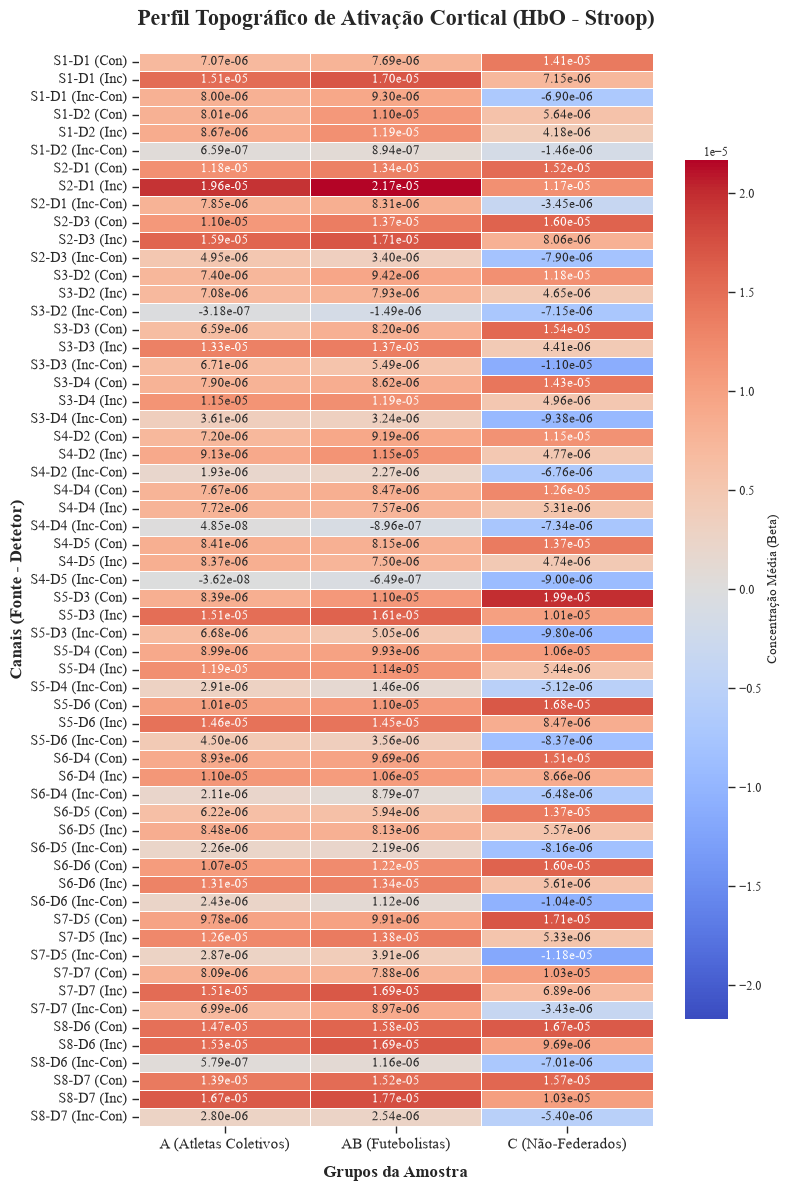

In [8]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura (Foco no Stroop)
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_stroop_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.csv"
caminho_stroop_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_Stroop.xlsx"
caminho_stroop = caminho_stroop_csv if caminho_stroop_csv.exists() else caminho_stroop_xlsx

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_stroop.suffix == '.csv':
    df_stroop = pd.read_csv(caminho_stroop, sep=';', decimal=',')
    if len(df_stroop.columns) < 5: df_stroop = pd.read_csv(caminho_stroop, sep=',', decimal='.')
else:
    df_stroop = pd.read_excel(caminho_stroop)

# ==========================================================
# 2. Definição da Amostra Analítica (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_stroop = 'ID' if 'ID' in df_stroop.columns else df_stroop.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_stroop['ID_Clean'] = df_stroop[col_id_stroop].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
else:
    is_individual = (~df_demo['Modalidade'].isin(mods_coletivas))

individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
df_analitica = df_demo.drop(individuais).copy()

df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C (Não-Federados)'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A (Atletas Coletivos)'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A (Atletas Coletivos)') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB (Futebolistas)'

df_mapeamento = pd.concat([df_analitica[['ID_Clean', 'Grupo_Análise']], df_fut[['ID_Clean', 'Grupo_Análise']]], ignore_index=True)
df_master = pd.merge(df_mapeamento, df_stroop, on='ID_Clean', how='inner')

# ==========================================================
# 3. Processamento dos Canais fNIRS para a Matriz
# ==========================================================
# Extrair apenas colunas de HbO
canais_hbo = [col for col in df_master.columns if col.startswith('HbO_') and col.endswith('_Beta')]

for col in canais_hbo:
    if df_master[col].dtype == 'object' or df_master[col].dtype == 'string':
        df_master[col] = df_master[col].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

# Calcular a média de ativação por grupo
df_medias = df_master.groupby('Grupo_Análise')[canais_hbo].mean().T

# Limpar o nome das linhas (canais) para ficar académico (ex: S1-D2 Incongruente)
novos_nomes = []
for nome in df_medias.index:
    partes = nome.split('_')
    # Ex: HbO_S1_D1_Inc_Beta -> 'S1-D1 (Inc)'
    # Lidar com diferenças de nomenclatura
    s_d = f"{partes[1]}-{partes[2]}"
    cond = partes[3] if len(partes) > 3 else ""
    novos_nomes.append(f"{s_d} ({cond})")

df_medias.index = novos_nomes

# Ordenar a matriz alfabeticamente pelos canais
df_medias = df_medias.sort_index()

# ==========================================================
# 4. Desenho do Heatmap
# ==========================================================
fig, ax = plt.subplots(figsize=(8, 12)) # Formato vertical (A4 friendly)

# Encontrar o valor máximo absoluto para centrar a paleta a zero perfeitamente
vmax = np.nanmax(np.abs(df_medias.values))
vmin = -vmax

# Heatmap com paleta divergente 'coolwarm' (padrão MNE-NIRS para neuroimagem)
sns.heatmap(df_medias, cmap='coolwarm', center=0, vmin=vmin, vmax=vmax, 
            annot=True, fmt=".2e", annot_kws={"size": 9, "family": "Times New Roman"},
            cbar_kws={'label': 'Concentração Média (Beta)', 'shrink': 0.8},
            linewidths=.5, ax=ax)

ax.set_title('Perfil Topográfico de Ativação Cortical (HbO - Stroop)', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Grupos da Amostra', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Canais (Fonte - Detetor)', fontsize=12, fontweight='bold')

plt.xticks(fontsize=11, rotation=0)
plt.yticks(fontsize=10)

plt.tight_layout()

caminho_figura = pasta_resultados / "Heatmap_Cortical_Stroop.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"Heatmap Cortical exportado com sucesso para: {caminho_figura.resolve()}")
plt.show()

# Fase 11b: Visualização Científica (Heatmap Cortical - Decision Making)

Geração do mapa de calor topográfico da ativação cortical (HbO) para a tarefa de Tomada de Decisão (*Decision Making*), estratificado pelos grupos da amostra (*Atletas Coletivos, Futebolistas, Não-Federados*).

**Objetivo Analítico:**
* Mapear a distribuição espacial da ativação no Córtex Pré-Frontal durante o processo de tomada de decisão desportiva/cognitiva.
* Fornecer a contrapartida visual ao heatmap do Stroop, permitindo evidenciar se a ausência de correlações fortes na Fase 10b se reflete também numa ativação cortical mais atenuada, distribuída ou homogénea entre os grupos.

Heatmap Cortical (Decision Making) exportado com sucesso para: C:\Users\guilh\Documents\GitHub\NIRS-UC-UMAD\data_subjects\Resultados_Neurofisiologicos\Heatmap_Cortical_DecisionMaking.png


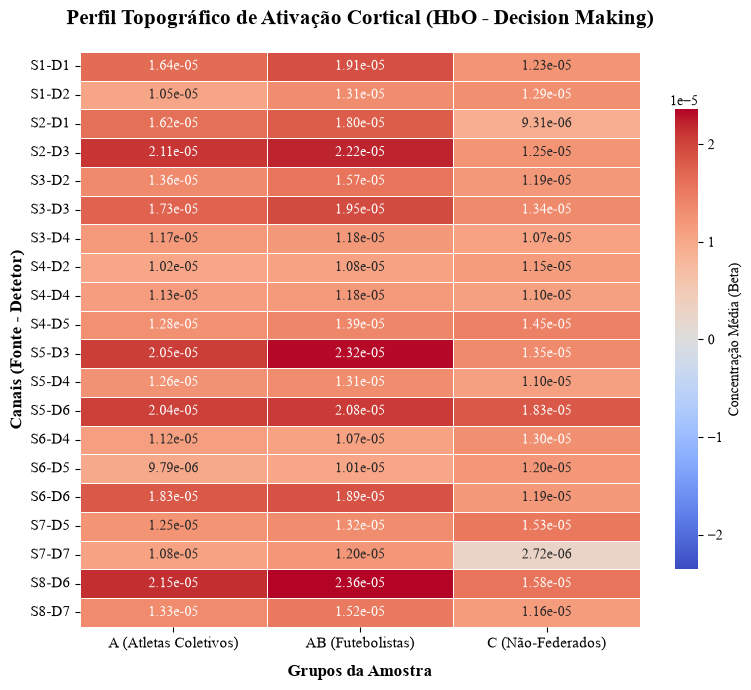

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['font.family'] = 'Times New Roman'

# ==========================================================
# 1. Configuração e Leitura (Decision Making)
# ==========================================================
pasta_dados = Path("../data_subjects")
pasta_resultados = pasta_dados / "Resultados_Neurofisiologicos"
caminho_demo = pasta_dados / "Merge_Dataset_Study_2.xlsx"

caminho_dm_csv = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.csv"
caminho_dm_xlsx = pasta_dados / "dataset_FINAL_SPA_fNIRS_DecisionMaking.xlsx"
caminho_dm = caminho_dm_csv if caminho_dm_csv.exists() else caminho_dm_xlsx

if "Merge Dataset" in pd.ExcelFile(caminho_demo).sheet_names:
    df_demo = pd.read_excel(caminho_demo, sheet_name="Merge Dataset")
else:
    df_demo = pd.read_excel(caminho_demo)

if caminho_dm.suffix == '.csv':
    df_dm = pd.read_csv(caminho_dm, sep=';', decimal=',')
    if len(df_dm.columns) < 5: df_dm = pd.read_csv(caminho_dm, sep=',', decimal='.')
else:
    df_dm = pd.read_excel(caminho_dm)

# ==========================================================
# 2. Definição da Amostra Analítica (N=51)
# ==========================================================
col_id_demo = 'ID' if 'ID' in df_demo.columns else df_demo.columns[0]
col_id_dm = 'ID' if 'ID' in df_dm.columns else df_dm.columns[0]

df_demo['ID_Clean'] = df_demo[col_id_demo].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()
df_dm['ID_Clean'] = df_dm[col_id_dm].astype(str).str.replace(r'\.0$', '', regex=True).str.strip()

df_demo['Estatuto'] = df_demo['É atualmente praticante federado de alguma modalidade desportiva?'].astype(str).str.strip().str.capitalize()
df_demo['Modalidade'] = df_demo['Indique a modalidade principal'].astype(str).str.strip().str.title()

mods_coletivas = ['Futebol', 'Futsal', 'Andebol', 'Voleibol', 'Basquetebol']
if 'No caso de ser desportista federado, a sua modalidade principal é:' in df_demo.columns:
    is_individual = df_demo['No caso de ser desportista federado, a sua modalidade principal é:'].astype(str).str.contains('Individual', case=False, na=False)
else:
    is_individual = (~df_demo['Modalidade'].isin(mods_coletivas))

individuais = df_demo[(df_demo['Estatuto'] == 'Sim') & is_individual].index
df_analitica = df_demo.drop(individuais).copy()

df_analitica['Grupo_Análise'] = pd.Series(dtype='object')
df_analitica.loc[df_analitica['Estatuto'] == 'Não', 'Grupo_Análise'] = 'C (Não-Federados)'
df_analitica.loc[df_analitica['Estatuto'] == 'Sim', 'Grupo_Análise'] = 'A (Atletas Coletivos)'

df_fut = df_analitica[(df_analitica['Grupo_Análise'] == 'A (Atletas Coletivos)') & (df_analitica['Modalidade'].str.contains('Futebol', case=False, na=False))].copy()
df_fut['Grupo_Análise'] = 'AB (Futebolistas)'

df_mapeamento = pd.concat([df_analitica[['ID_Clean', 'Grupo_Análise']], df_fut[['ID_Clean', 'Grupo_Análise']]], ignore_index=True)
df_master = pd.merge(df_mapeamento, df_dm, on='ID_Clean', how='inner')

# ==========================================================
# 3. Processamento dos Canais fNIRS para a Matriz (DM)
# ==========================================================
canais_hbo = [col for col in df_master.columns if col.startswith('HbO_') and col.endswith('_Beta')]

for col in canais_hbo:
    if df_master[col].dtype == 'object' or df_master[col].dtype == 'string':
        df_master[col] = df_master[col].astype(str).str.replace(',', '.').apply(pd.to_numeric, errors='coerce')

df_medias = df_master.groupby('Grupo_Análise')[canais_hbo].mean().T

# Limpeza robusta do nome dos canais (ex: S1-D2, ignorando o "Beta")
novos_nomes = []
for nome in df_medias.index:
    partes = nome.split('_')
    s_d = f"{partes[1]}-{partes[2]}"
    
    # Se houver uma condição escrita no meio (ex: HbO_S1_D1_Cond1_Beta)
    if len(partes) > 4 and partes[-1].lower() == 'beta':
        cond = "_".join(partes[3:-1])
        novos_nomes.append(f"{s_d} ({cond})")
    elif len(partes) > 3 and partes[3].lower() != 'beta':
        cond = partes[3]
        novos_nomes.append(f"{s_d} ({cond})")
    else:
        novos_nomes.append(s_d)

df_medias.index = novos_nomes
df_medias = df_medias.sort_index()

# ==========================================================
# 4. Desenho do Heatmap
# ==========================================================
# Ajustar a altura da figura dinamicamente com base no número de canais exportados no DM
altura_fig = max(5, len(df_medias) * 0.35)
fig, ax = plt.subplots(figsize=(8, altura_fig)) 

vmax = np.nanmax(np.abs(df_medias.values))
if vmax == 0 or np.isnan(vmax): 
    vmax = 1e-5
vmin = -vmax

sns.heatmap(df_medias, cmap='coolwarm', center=0, vmin=vmin, vmax=vmax, 
            annot=True, fmt=".2e", annot_kws={"size": 10, "family": "Times New Roman"},
            cbar_kws={'label': 'Concentração Média (Beta)', 'shrink': 0.8},
            linewidths=.5, ax=ax)

ax.set_title('Perfil Topográfico de Ativação Cortical (HbO - Decision Making)', fontsize=15, fontweight='bold', pad=20)
ax.set_xlabel('Grupos da Amostra', fontsize=12, fontweight='bold', labelpad=10)
ax.set_ylabel('Canais (Fonte - Detetor)', fontsize=12, fontweight='bold')

plt.xticks(fontsize=11, rotation=0)
plt.yticks(fontsize=11)

plt.tight_layout()

caminho_figura = pasta_resultados / "Heatmap_Cortical_DecisionMaking.png"
plt.savefig(caminho_figura, dpi=300, bbox_inches='tight')

print(f"Heatmap Cortical (Decision Making) exportado com sucesso para: {caminho_figura.resolve()}")
plt.show()